# Лабораторная работа №2: Семантическая сегментация

## Цель
Освоить методы семантической сегментации изображений на примере архитектур UNet и DeepLabv3+, изучить метрики качества (IoU, Dice).

## Теория
- Классификация vs. детекция vs. сегментация.
- Архитектура UNet и её особенности.
- DeepLabv3+ и dilated convolutions.
- Метрики: IoU, Dice.

## Задания
1. Выберите модель (UNet или DeepLabv3+).
2. Возьмите датасет (Carvana, Pascal VOC или Cityscapes subset).
3. Подготовьте данные и обучите модель сегментации.
4. Оцените качество с использованием IoU и Dice.
5. Визуализируйте результаты (картинки с наложением предсказанных масок).
6. Проведите эксперимент с разными размерами входного изображения или с аугментациями.

## Вопросы
1. Почему accuracy плохо отражает качество сегментации?
2. Чем UNet отличается от "обычной" CNN?

## Требуемое содержание файла проекта
- Иллюстрации входных изображений и масок.
- Примеры предсказаний модели.
- Сравнительный анализ экспериментов.
- Ответы на контрольные вопросы.

# **Студент: Ерзикова Е.А., группа 6233**

# **Выбранная модель:** UNet (с предобученным энкодером ResNet34)

# **Выбранный датасет:** Pascal VOC 2012 (21 класс)

## 1. Теоретическая часть

### 1.1. Классификация vs. Детекция vs. Сегментация
* **Классификация** предсказывает один класс для всего изображения (например, "на фото есть машина").
* **Детекция** находит ограничивающие рамки (bounding boxes) для объектов.
* **Семантическая сегментация** выполняет попиксельную классификацию, присваивая каждому пикселю изображения определенный класс (например, все пиксели машины окрашиваются в один цвет).

### 1.2. Архитектура UNet и её особенности
UNet — это полносверточная сеть (fully convolutional network) с архитектурой «энкодер-декодер» в форме буквы U.
* **Энкодер:** уменьшает пространственную размерность и извлекает признаки.
* **Декодер:** восстанавливает пространственное разрешение (up-convolution).
* **Skip Connections (Ключевая особенность):** соединяют слои энкодера с соответствующими слоями декодера. Это позволяет передавать высокочастотные детали (границы, текстуры), которые теряются при сжатии, обеспечивая точную локализацию объектов.

### 1.3. Метрики: IoU и Dice

* **IoU (Intersection over Union):** отношение площади пересечения предсказанной и истинной маски к площади их объединения:

$$
IoU = \frac{TP}{TP + FP + FN}
$$

* **Dice Coefficient:** удвоенное отношение площади пересечения к сумме площадей масок:

$$
Dice = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}
$$

где:
- **TP** (True Positive) — пиксели объекта, предсказанные верно;
- **FP** (False Positive) — пиксели фона, ошибочно предсказанные как объект;
- **FN** (False Negative) — пиксели объекта, ошибочно предсказанные как фон.

**Связь метрик:** $IoU = \frac{Dice}{2 - Dice}$

# Установка и импорты

In [ ]:
!pip install -q albumentations segmentation-models-pytorch

import os, random, copy
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torchvision.datasets import VOCSegmentation

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

# Фиксируем сиды для воспроизводимости
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Устройство: {device}')

Устройство: cuda


# Настройка гиперпараметров

In [ ]:
BASELINE_SIZE = 256
LARGE_SIZE    = 512
EPOCHS        = 20
LR            = 1e-4
BATCH         = 16

NUM_CLASSES   = 21  # 0 = фон, 1-20 = классы Pascal VOC
IGNORE_IDX    = 255 # Границы объектов

# Подготовка данных (Pascal VOC 2012)

Скачиваем датасет и разбиваем его на три части: Train (70%), Validation (15%) и Test (15%).


In [ ]:
print("Скачивание Pascal VOC 2012...")
voc_train = VOCSegmentation(root='./data', year='2012', image_set='train', download=True)
voc_val   = VOCSegmentation(root='./data', year='2012', image_set='val', download=True)

df_train_full = pd.DataFrame({'img_path': voc_train.images, 'mask_path': voc_train.masks})
df_val_full   = pd.DataFrame({'img_path': voc_val.images,   'mask_path': voc_val.masks})
df_all = pd.concat([df_train_full, df_val_full], ignore_index=True)

# Разбиваем 70 / 15 / 15
all_indices = list(range(len(df_all)))
random.shuffle(all_indices)
train_size = int(len(df_all) * 0.7)
val_size = int(len(df_all) * 0.15)

df_train = df_all.iloc[all_indices[:train_size]].reset_index(drop=True)
df_val   = df_all.iloc[all_indices[train_size:train_size + val_size]].reset_index(drop=True)
df_test  = df_all.iloc[all_indices[train_size + val_size:]].reset_index(drop=True)

train_p = (df_train['img_path'].tolist(), df_train['mask_path'].tolist())
val_p   = (df_val['img_path'].tolist(),   df_val['mask_path'].tolist())
test_p  = (df_test['img_path'].tolist(),  df_test['mask_path'].tolist())

print(f"Train: {len(train_p[0])} | Val: {len(val_p[0])} | Test: {len(test_p[0])}")

Скачивание Pascal VOC 2012...


100%|██████████| 2.00G/2.00G [00:17<00:00, 115MB/s]


Train: 2039 | Val: 436 | Test: 438


# Класс Dataset и аугментации

Создаем кастомный класс `VOCDataset` для PyTorch:
* Используем библиотеку **Albumentations** для ресайза и аугментаций (отражение, поворот, изменение цвета).
* Маску принудительно приводим к типу `.long()`. Это требование функции потерь `CrossEntropyLoss`, которая ожидает целочисленные метки классов (тип `int64`), а не `int32`, который выдает Albumentations по умолчанию.

In [ ]:
class VOCDataset(Dataset):
    def __init__(self, img_paths, mask_paths, size=256, augment=False):
        self.img_paths, self.mask_paths = img_paths, mask_paths
        tf = [A.Resize(size, size)]
        if augment:
            tf += [
                A.HorizontalFlip(p=0.5),
                A.Rotate(limit=10, p=0.5),
                A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05, p=0.5),
            ]
        tf += [A.Normalize(mean=(0.485,0.456,0.406), std=(0.229,0.224,0.225)), ToTensorV2()]
        self.tf = A.Compose(tf)

    def __len__(self): return len(self.img_paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.img_paths[i]), cv2.COLOR_BGR2RGB)
        mask = np.array(Image.open(self.mask_paths[i]), dtype=np.int64)
        out = self.tf(image=img, mask=mask)
        return out['image'], out['mask'].long()

# Архитектура UNet

Для получения высокого качества за короткое время используем UNet с предобученным энкодером **ResNet34** (веса ImageNet).

In [ ]:
def get_pretrained_unet():
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=NUM_CLASSES,
    )
    return model

# Функции потерь, метрики и процесс обучения

В задачах сегментации с сильным дисбалансом классов (когда фона на картинке 80-90%) обычная кросс-энтропия (CE) работает плохо. Модель просто учится предсказывать фон.

Поэтому используем **ComboLoss** (комбинацию CrossEntropy + Dice Loss). Dice Loss фокусирует внимание модели на совпадении предсказанных масок с реальными объектами.

Также реализована функция `evaluate`, которая считает метрики **mIoU** и **mDice** по всем 21 классу (игнорируя границы).

In [ ]:
class ComboLoss(nn.Module):
    def __init__(self, weight_ce=0.5, weight_dice=0.5, ignore_index=255):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(ignore_index=ignore_index)
        self.w_ce = weight_ce
        self.w_dice = weight_dice

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)

        probs = torch.softmax(logits, dim=1)
        targets_valid = targets.clone()
        targets_valid[targets_valid == 255] = 0
        target_one_hot = F.one_hot(targets_valid, num_classes=logits.shape[1]).permute(0, 3, 1, 2).float()

        mask = (targets != 255).unsqueeze(1).float()

        intersection = torch.sum(probs * target_one_hot * mask, dim=(0, 2, 3))
        union = torch.sum((probs + target_one_hot) * mask, dim=(0, 2, 3))

        dice = (2 * intersection + 1e-7) / (union + 1e-7)
        dice_loss = 1 - dice.mean()

        return self.w_ce * ce_loss + self.w_dice * dice_loss

def train_epoch(model, loader, opt, loss_fn):
    model.train(); total = 0.0
    for x, y in tqdm(loader, leave=False):
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward(); opt.step()
        total += loss.item() * x.size(0)
    return total / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval(); total_loss = 0.0; n = 0
    intersections = torch.zeros(NUM_CLASSES).to(device)
    unions = torch.zeros(NUM_CLASSES).to(device)
    pred_sums = torch.zeros(NUM_CLASSES).to(device)
    target_sums = torch.zeros(NUM_CLASSES).to(device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * x.size(0); n += x.size(0)

        preds = torch.argmax(logits, dim=1)
        valid = (y != IGNORE_IDX)
        preds, y_valid = preds[valid], y[valid]

        for cls in range(NUM_CLASSES):
            p_c = (preds == cls); t_c = (y_valid == cls)
            intersections[cls] += (p_c & t_c).sum()
            unions[cls] += (p_c | t_c).sum()
            pred_sums[cls] += p_c.sum()
            target_sums[cls] += t_c.sum()

    ious, dices = [], []
    for cls in range(NUM_CLASSES):
        if unions[cls] == 0: continue
        ious.append((intersections[cls] / unions[cls]).item())
        dices.append((2 * intersections[cls] / (pred_sums[cls] + target_sums[cls] + 1e-7)).item())

    return total_loss / n, np.mean(ious), np.mean(dices)

def run_experiment(name, size, augment, batch_size, epochs=EPOCHS):
    print(f'\n{"="*60}\nЭксперимент: {name}\n{"="*60}')
    train_ds = VOCDataset(*train_p, size=size, augment=augment)
    val_ds   = VOCDataset(*val_p,   size=size, augment=False)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

    model = get_pretrained_unet().to(device)
    opt = Adam(model.parameters(), lr=LR)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=2)

    loss_fn = ComboLoss(weight_ce=0.5, weight_dice=0.5, ignore_index=IGNORE_IDX).to(device)

    best = {'dice': -1, 'iou': 0}
    for ep in range(1, epochs+1):
        tr = train_epoch(model, train_loader, opt, loss_fn)
        va, iou, dice = evaluate(model, val_loader, loss_fn)

        scheduler.step(dice)

        if dice > best['dice']:
            best = {'dice': dice, 'iou': iou, 'state': copy.deepcopy(model.state_dict())}
        print(f'Epoch {ep:02d}/{epochs} | Loss: {tr:.3f} | Val mIoU: {iou:.4f} | Val mDice: {dice:.4f}')

    model.load_state_dict(best['state'])
    return {'name': name, 'model': model, 'best_dice': best['dice'], 'best_iou': best['iou']}

# Проведение экспериментов

Запускаем три серии обучения:
1. **Baseline (256x256):** без аугментаций.
2. **With Augmentations (256x256):** с аугментациями (отражения, повороты).
3. **Large Size (512x512):** без аугментаций, но с увеличенным разрешением (batch_size уменьшен до 8, чтобы хватило ресурсов в colab).

In [ ]:
# 1. Базовая модель (256x256, без аугментаций)
exp_baseline = run_experiment('Baseline (256)', size=256, augment=False, batch_size=BATCH, epochs=20)

# 2. Модель с аугментациями (256x256)
exp_aug = run_experiment('With Augmentations (256)', size=256, augment=True, batch_size=BATCH, epochs=20)

# 3. Модель с увеличенным размером (512x512)
exp_large = run_experiment('Large Size (512)', size=512, augment=False, batch_size=8, epochs=20)


Эксперимент: Baseline (256)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/128 [00:00<?, ?it/s]

...

Epoch 18/20 | Loss: 0.351 | Val mIoU: 0.5702 | Val mDice: 0.7092


  0%|          | 0/255 [00:00<?, ?it/s]

Epoch 19/20 | Loss: 0.368 | Val mIoU: 0.5330 | Val mDice: 0.6776


  0%|          | 0/255 [00:00<?, ?it/s]

Epoch 20/20 | Loss: 0.342 | Val mIoU: 0.5608 | Val mDice: 0.7018


В ходе работы было обучено три конфигурации UNet (энкодер ResNet34, предобученный на ImageNet) в течение 20 эпох. По результатам логов можно сделать следующие выводы:


**Базовый эксперимент** показал результат mIoU 0.5628, mDice 0.6971. Модель к концу обучения демонстрирует **нестабильность** (провалы на 17-18 эпохах).


**Использование аугментаций** (отражение, поворот, изменение цвета) позволило достичь наивысших пиковых метрик (mIoU 0.5817, mDice 0.7139). Кроме того, аугментации сгладили процесс обучения — метрики росли **стабильно**, без резких перепадов, что свидетельствует о снижении эффекта переобучения. Модель стала лучше обобщать данные.

**Увеличение разрешения до 512x512** дало отличный результат (mIoU 0.5786, mDice 0.7173). Главное преимущество — **скорость сходимости**. Модель вышла на высокие метрики раньше остальных (к 11-й эпохе). Высокое разрешение помогает сети лучше распознавать мелкие детали, однако требует в 3-4 раза больше времени на обучение (batch_size пришлось уменьшить до 8).


# Визуализация результатов

Для наглядного сравнения моделей фиксируем 6 случайных изображений из тестовой выборки.

На графиках представлены 4 колонки:
1. **Input** — исходное изображение.
2. **Ground Truth (GT)** — истинная маска (цвета соответствуют палитре Pascal VOC).
3. **Prediction** — предсказание модели.
4. **Overlay** — наложение предсказания на исходное изображение для оценки точности границ.

In [ ]:
import matplotlib.pyplot as plt

# Официальная палитра цветов Pascal VOC
VOC_COLORMAP = np.array([
    [0, 0, 0], [128, 0, 0], [0, 128, 0], [128, 128, 0], [0, 0, 128], [128, 0, 128],
    [0, 128, 128], [128, 128, 128], [64, 0, 0], [192, 0, 0], [64, 128, 0], [192, 128, 0],
    [64, 0, 128], [192, 0, 128], [64, 128, 128], [192, 128, 128], [0, 64, 0], [128, 64, 0],
    [0, 192, 0], [128, 192, 0], [0, 64, 128]
], dtype=np.uint8)

def decode_segmap(mask):
    rgb = np.zeros((mask.shape[0], mask.shape[1], 3), dtype=np.uint8)
    for cls in range(NUM_CLASSES):
        rgb[mask == cls] = VOC_COLORMAP[cls]
    return rgb

def visualize(model, dataset, n=6, title='', fixed_idxs=None):
    model.eval()
    mean = np.array([0.485,0.456,0.406]); std = np.array([0.229,0.224,0.225])

    if fixed_idxs is not None:
        idxs = fixed_idxs
    else:
        idxs = np.random.choice(len(dataset), min(n, len(dataset)), replace=False)

    fig, axes = plt.subplots(len(idxs), 4, figsize=(16, len(idxs) * 3.5))
    if len(idxs) == 1: axes = axes[None]

    for i, idx in enumerate(idxs):
        img, mask = dataset[idx]
        with torch.no_grad():
            logits = model(img.unsqueeze(0).to(device))
            pred = torch.argmax(logits, dim=1)[0].cpu().numpy()

        img_np = (img.permute(1,2,0).numpy() * std + mean).clip(0, 1)
        gt_np = mask.numpy(); gt_np[gt_np == IGNORE_IDX] = 0

        pred_rgb = decode_segmap(pred); gt_rgb = decode_segmap(gt_np)
        overlay = 0.6 * img_np + 0.4 * (pred_rgb / 255.0)

        axes[i,0].imshow(img_np);   axes[i,0].set_title('Input');        axes[i,0].axis('off')
        axes[i,1].imshow(gt_rgb);   axes[i,1].set_title('Ground Truth'); axes[i,1].axis('off')
        axes[i,2].imshow(pred_rgb); axes[i,2].set_title('Prediction');   axes[i,2].axis('off')
        axes[i,3].imshow(overlay);  axes[i,3].set_title('Overlay');      axes[i,3].axis('off')

    fig.suptitle(title, fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.95])

    plt.show()

# Берем тестовую выборку
test_ds_256 = VOCDataset(*test_p, size=256, augment=False)
test_ds_512 = VOCDataset(*test_p, size=512, augment=False)

np.random.seed(123)
fixed_indices = np.random.choice(len(test_ds_256), 6, replace=False)
print(f"Выбранные индексы для визуализации: {fixed_indices}")


Выбранные индексы для визуализации: [ 13 297 142 201 292 377]


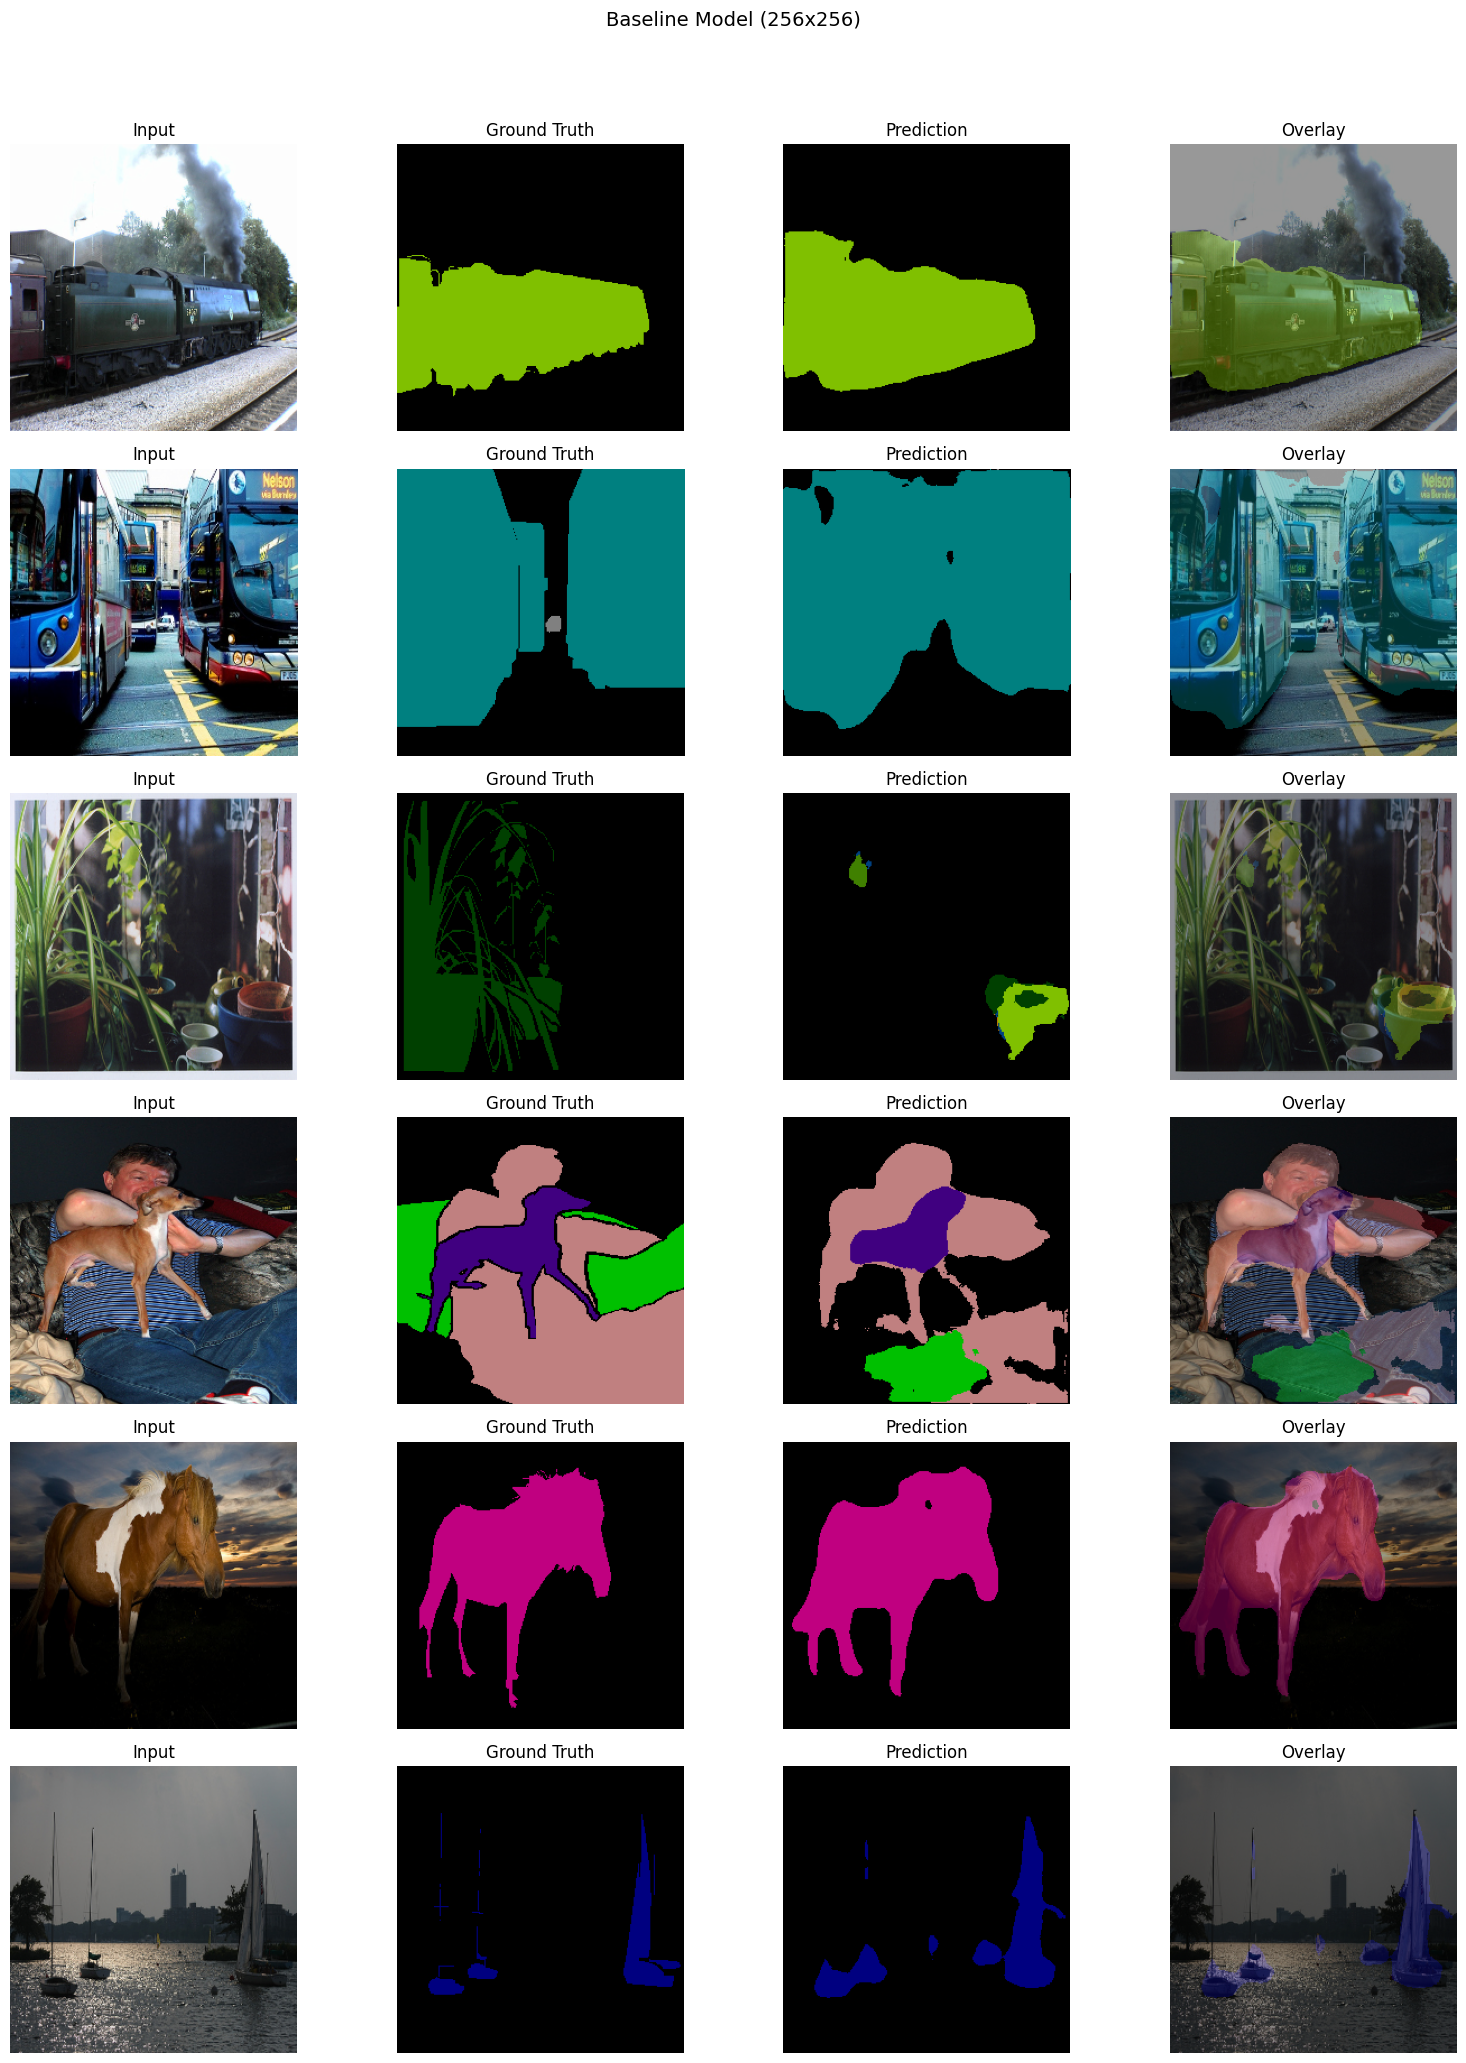

In [ ]:

# 1. Baseline
visualize(exp_baseline['model'], test_ds_256, title='Baseline Model (256x256)', fixed_idxs=fixed_indices)

## Анализ Baseline Model (256x256):

Крупные и контрастные объекты (лошадь, поезд, человек) модель сегментирует очень уверенно. Значит предобученный энкодер ResNet34 отлично извлекает базовые признаки форм и текстур.

Мелкие и тонкие объекты (листья растений, мачты лодок) теряются. Это ограничение разрешения.

Сложные сцены с перекрытиями (автобусы) вызывают трудности. Модель может путать границы объектов или пропускать их.

Ложные срабатывания (зеленое пятно у человека) случаются из-за того, что модель видит похожие текстуры и ошибочно классифицирует их как объект интерьера.

 Маска почти идеально повторяет силуэт лошади, но немного лишнего.

Модель нашла основные паруса, но полностью проигнорировала тонкие мачты. Кроме того, появился артефакт в виде синего пятна прямо на воде, где никакой лодки нет.

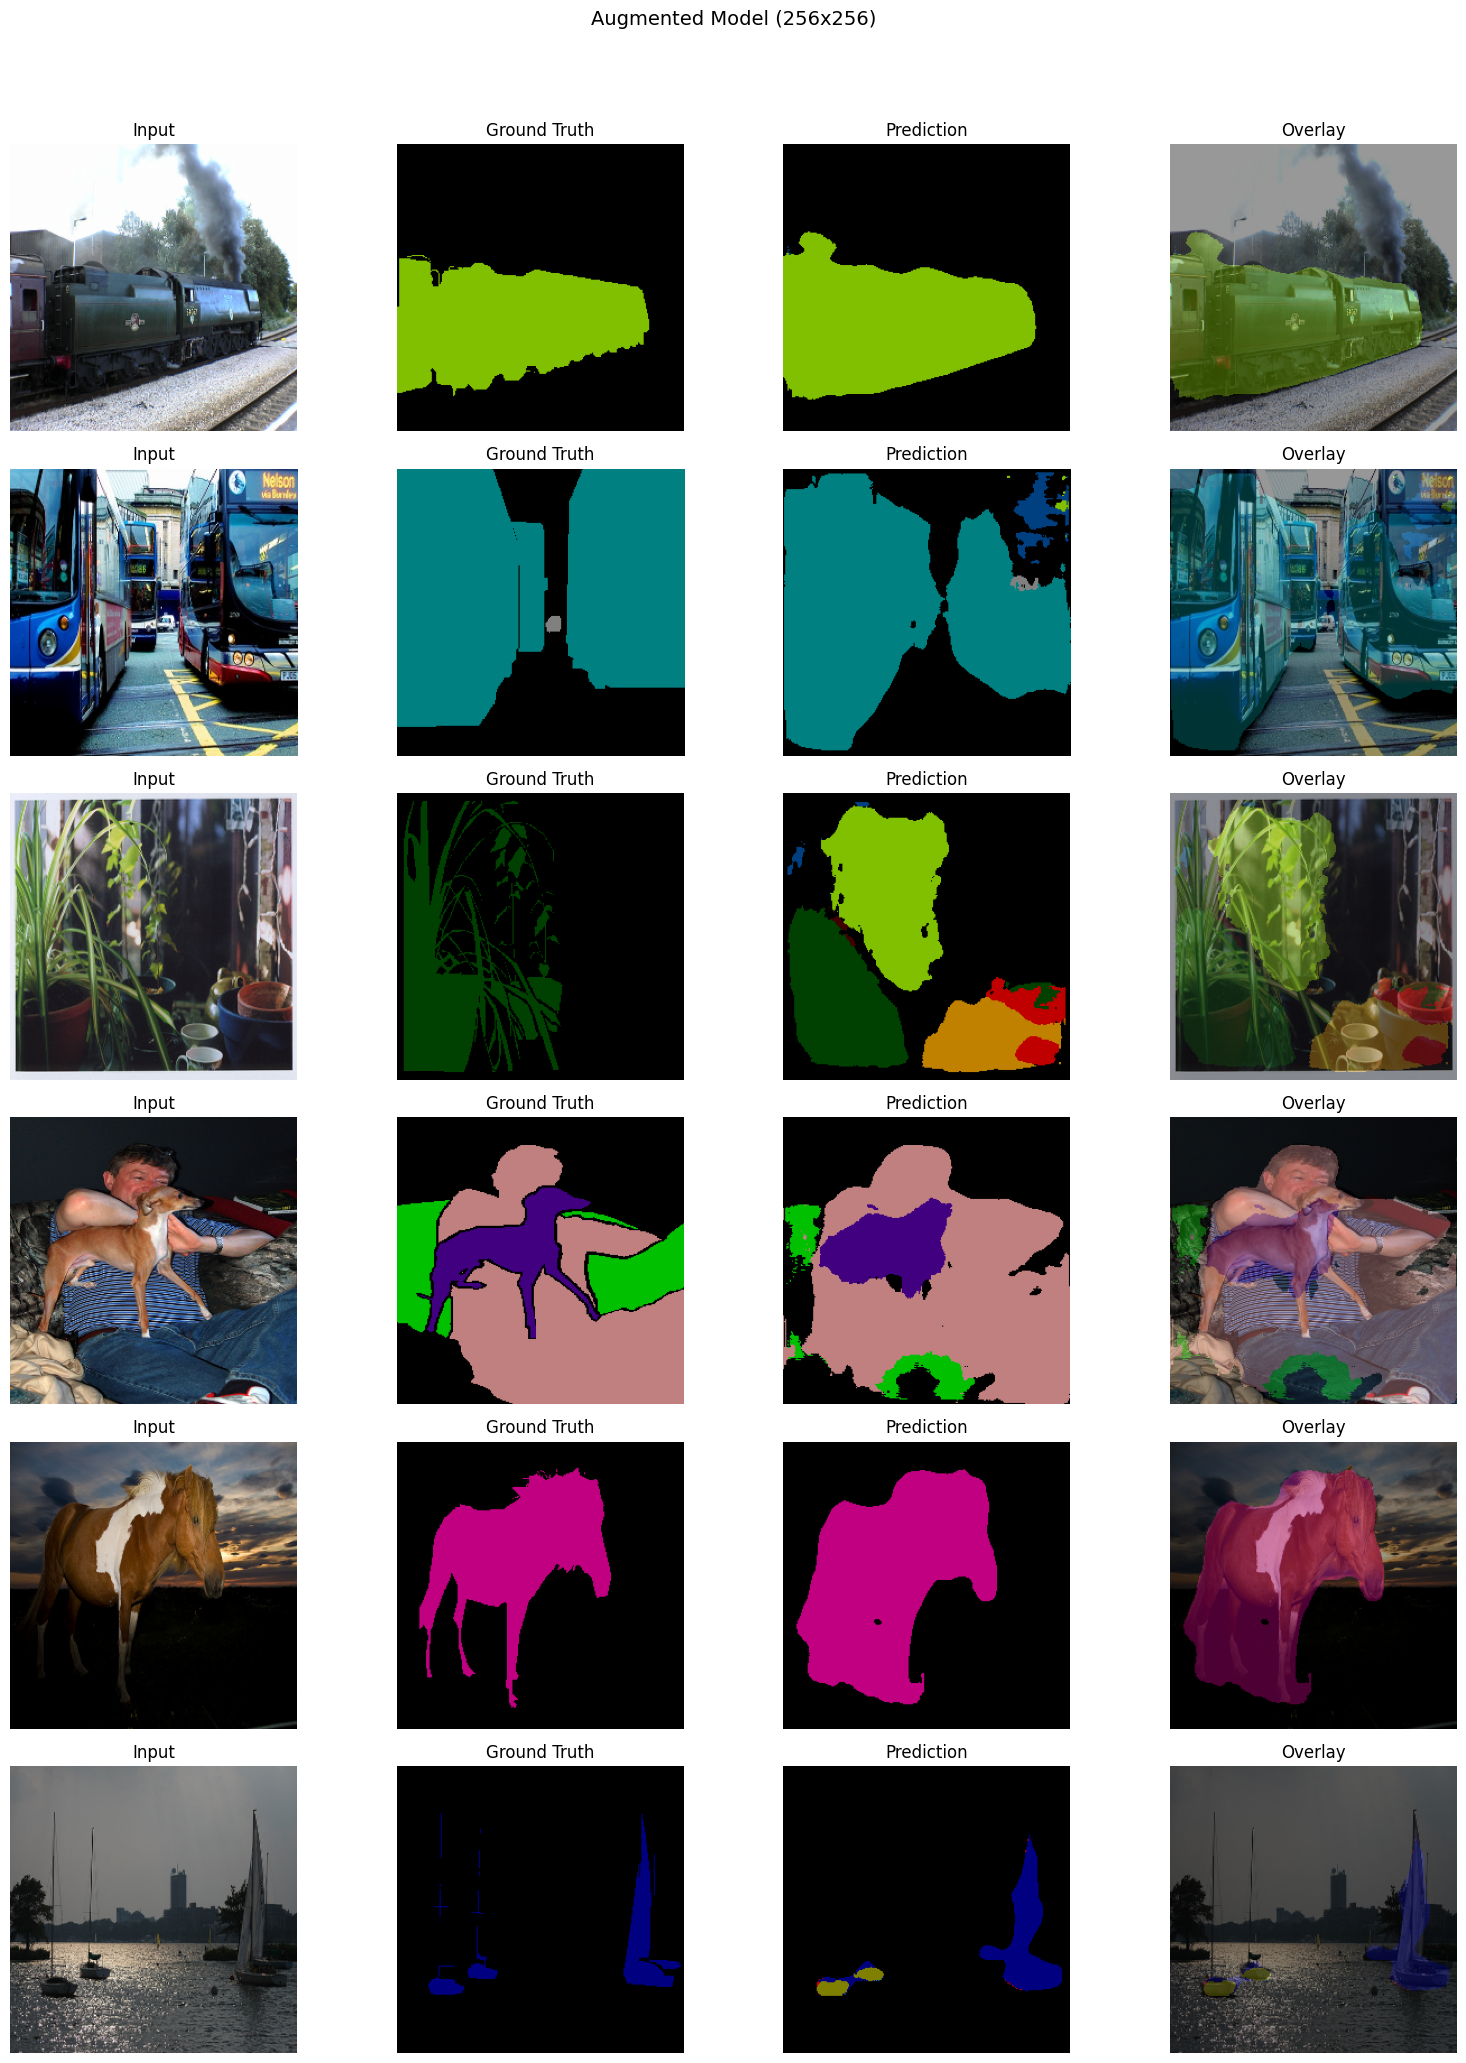

In [ ]:
# 2. Augmented
visualize(exp_aug['model'], test_ds_256, title='Augmented Model (256x256)', fixed_idxs=fixed_indices)


## Анализ Augmented Model (256x256)

Результат практически идентичен Baseline. Модель уверенно выделила поезд, форма маски стабильна. Аугментации не сломали распознавание этого объекта.

В отличие от Baseline, где правый автобус был полностью потерян, модель с аугментациями смогла его найти и выделить. Модель стала лучше справляться со сложными сценами и множественными объектами.

Ухудшение у растений. Модель выдала огромные цветные пятна (желтое, красное), которых нет в истинной маске. Аугментации заставили модель слишком остро реагировать на изменение цвета и текстуры, из-за чего перепутаны горшки и фон с другими объектами.

Модель увереннее выделила и человека, и собаку. Форма маски человека стала даже чуть более гладкой, чем в Baseline.

Ухудшение формы у лошади. Если Baseline-модель аккуратно обвела ноги лошади, то здесь модель предсказала огромное бесформенное пятно. Аугментации поворотов могли сбить модель с толку, и она перестала четко понимать геометрию.

Небольшое улучшение у лодок. Модель нашла правую лодку почти идеально и выделила часть левой. Артефакты на воде в виде желтых пятен, но общая структура парусов стала четче.

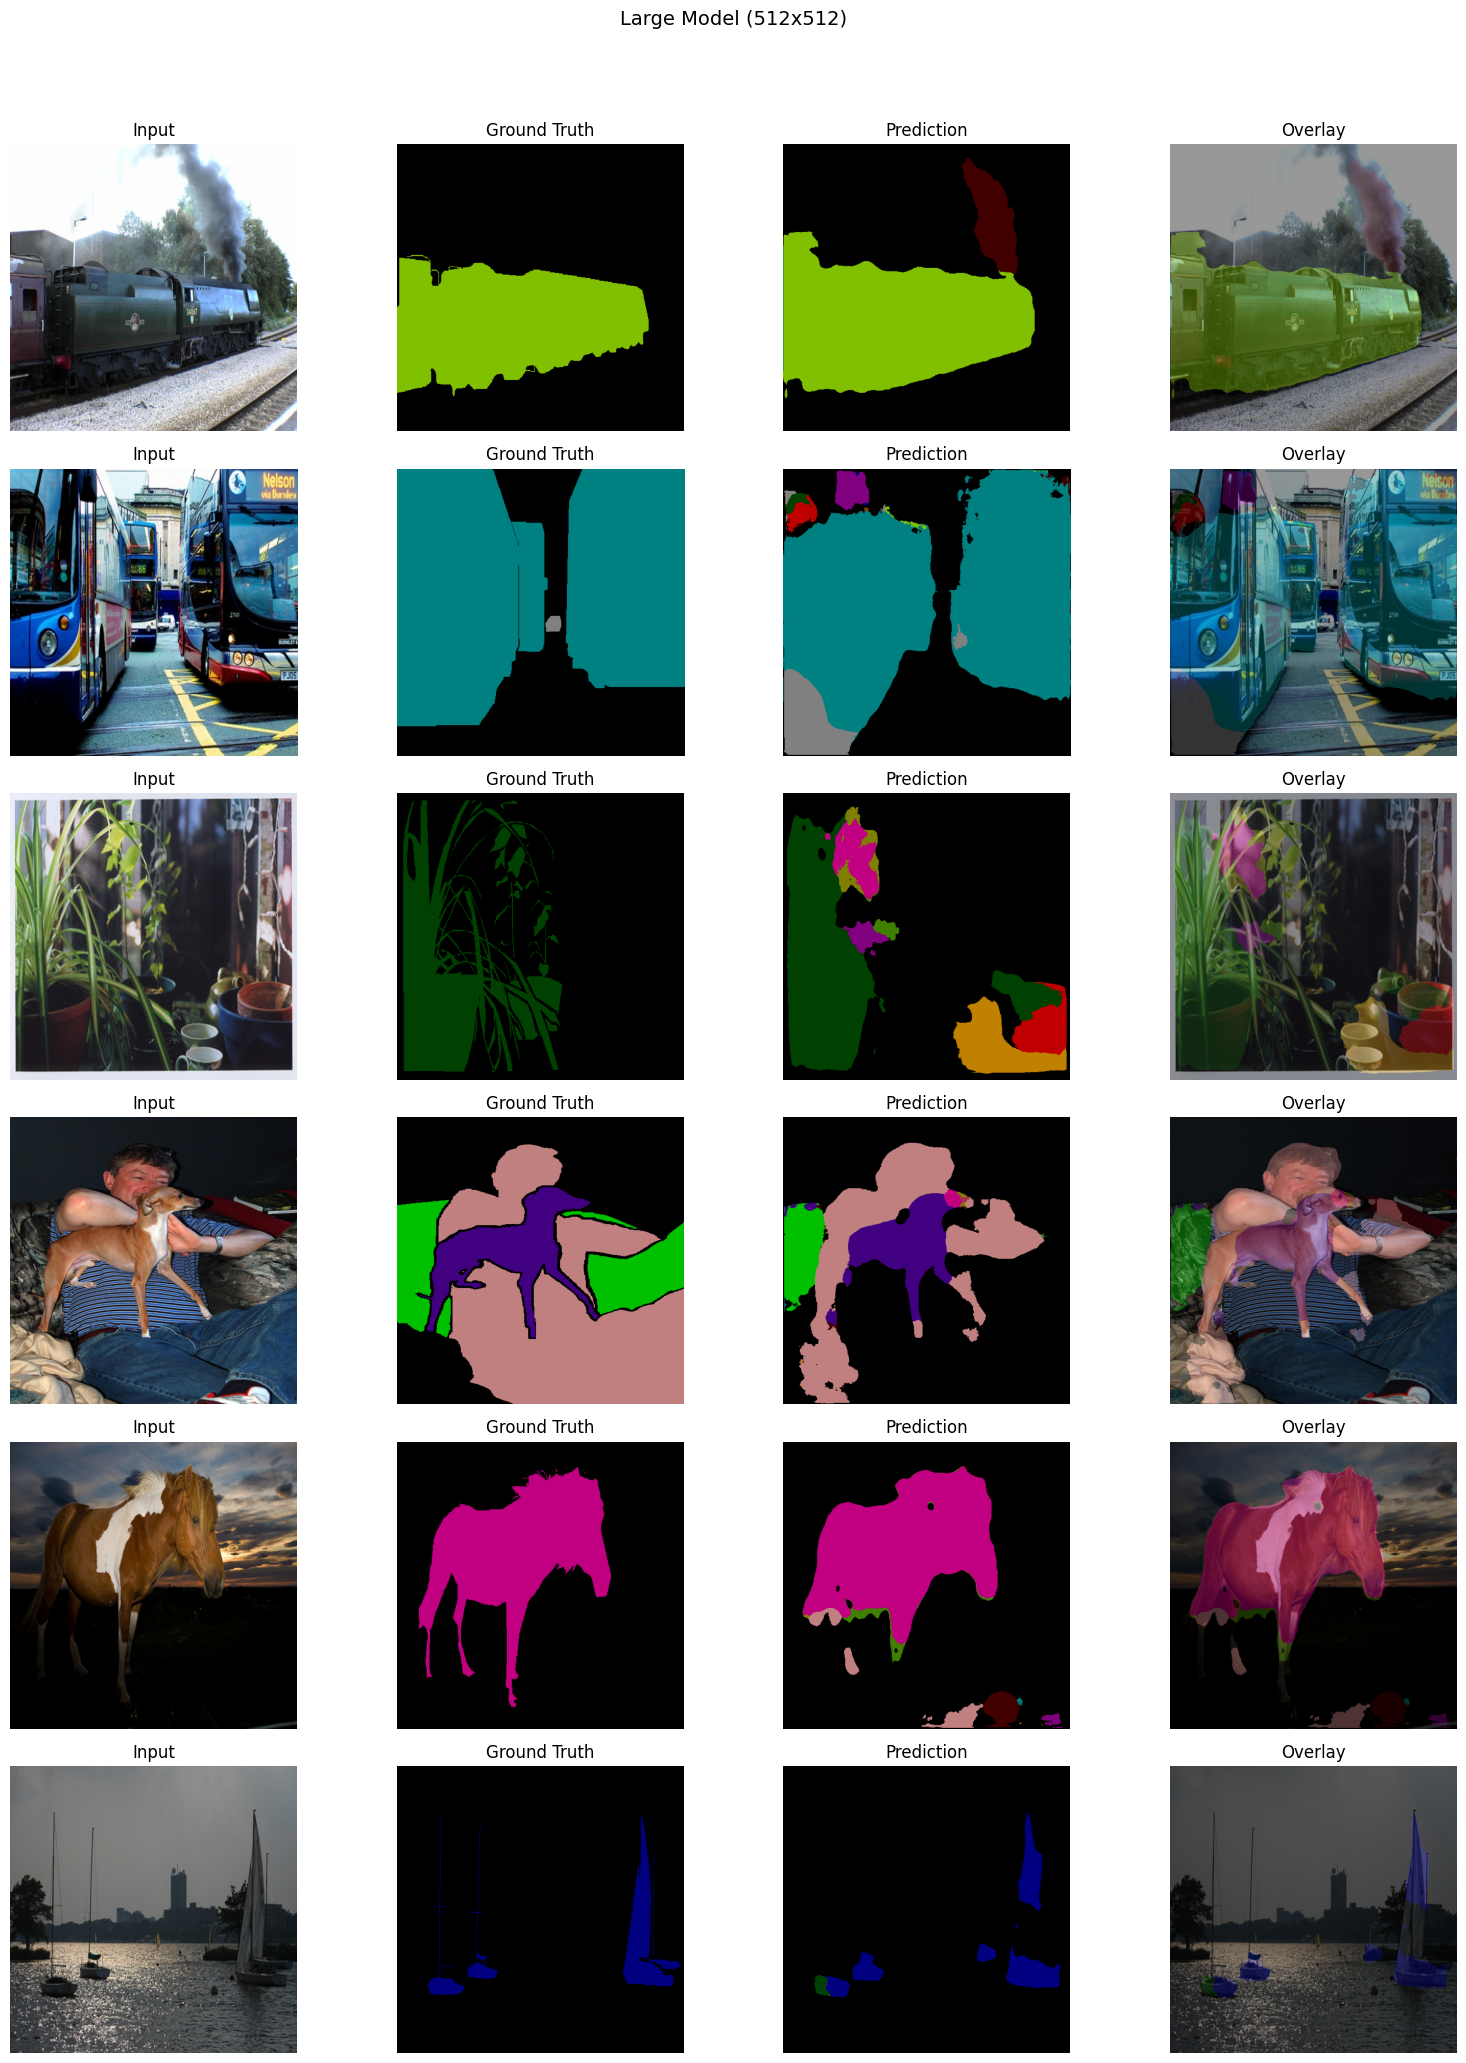

In [ ]:
# 3. Large (512x512)
visualize(exp_large['model'], test_ds_512, title='Large Model (512x512)', fixed_idxs=fixed_indices)

## Анализ Large Model (512x512)

Форма локомотива стала значительно более гладкой и точной, без «рваных» краев, которые были на 256x256. Появилось ложное срабатывание (коричневое пятно в небе справа).

Модель на 512x512 уверенно выделила оба автобуса и сделала это более аккуратно, чем Augmented-модель. Появились небольшие артефакты на заднем плане.

Тонкие листья растений по-прежнему остаются сложными для сегментации. Появилось много ложных цветных пятен (желтые, красные, розовые) на горшках и фоне.

Лапы собаки (фиолетовый цвет) и контуры человека (розовый) стали гораздо более четкими и детализированными, чем на 256x256. Видно, что высокое разрешение помогло модели лучше понять анатомию и отделить объекты друг от друга.

Силуэт лошади стал ровным и аккуратным. Внизу есть пара ложных пятен, но сама лошадь практически выделена.

Модель стала лучше выделять паруса, но все еще не видит тонкие мачты. Артефакты зеленых пятен на воде остались, но контуры самих лодок стали более правильными.





**В итоге, сравнивая визуализации предсказаний, можно проследить четкую взаимосвязь между настройками обучения и качеством масок:**

Baseline (256×256): Хорошо справляется с крупными, изолированными объектами (лошадь, поезд). Однако теряет мелкие детали и объекты в сложных сценах (пропустил один автобус).

Augmented (256×256): Благодаря аугментациям модель стала лучше находить объекты в сложных условиях (нашла оба автобуса). Однако агрессивные искажения (повороты, изменение цвета) привели к тому, что модель начала придумывать несуществующие объекты (цветные пятна на растениях, бесформенное пятно вместо лошади).

Large Size (512×512): Показал наилучшее визуальное качество. Увеличение разрешения позволило сохранить высокочастотные детали: ноги лошади и собаки прорисованы четко, границы автобусов ровные, а артефакты, вызванные аугментациями, исчезли. Тонкие структуры (листья, мачты) по-прежнему сложны для сети, но общая точность границ (Overlay) значительно выше.

In [ ]:
# Собираем метрики в таблицу
results = pd.DataFrame([
    {'Эксперимент': 'Baseline (256x256)', 'mIoU': exp_baseline['best_iou'], 'mDice': exp_baseline['best_dice']},
    {'Эксперимент': 'С аугментациями (256x256)', 'mIoU': exp_aug['best_iou'], 'mDice': exp_aug['best_dice']},
    {'Эксперимент': 'Большой размер (512x512)', 'mIoU': exp_large['best_iou'], 'mDice': exp_large['best_dice']},
]).round(4)

print("\n=== СРАВНИТЕЛЬНЫЙ АНАЛИЗ ЭКСПЕРИМЕНТОВ ===")
print(results.to_string(index=False))


=== СРАВНИТЕЛЬНЫЙ АНАЛИЗ ЭКСПЕРИМЕНТОВ ===
              Эксперимент   mIoU  mDice
       Baseline (256x256) 0.5628 0.6971
С аугментациями (256x256) 0.5817 0.7139
 Большой размер (512x512) 0.5786 0.7173


**Модели «С аугментациями» и «Large Size» показали практически одинаковый результа, значительно превзойдя базовую модель.**

Однако, **модель «С аугментациями (256x256)» является наиболее сбалансированным и оптимальным решением.** Она достигает наивысшего показателя mIoU (0.5817), обладает лучшей обобщающей способностью благодаря аугментациям и требует в несколько раз меньше вычислительных ресурсов (памяти и времени на обучение), чем модель на 512x512.

**Модель Large Size (512x512) рекомендуется использовать только в тех случаях, когда критически важна точность мелких деталей (тонкие границы объектов), а вычислительные ресурсы не ограничены.**

# **Ответы на вопросы**

**1. Почему accuracy плохо отражает качество сегментации?**

Метрика Accuracy (доля правильно классифицированных пикселей от общего их числа) крайне ненадежна в задачах сегментации из-за сильного дисбаланса классов.
На типичном изображении (например, в датасете Pascal VOC) фон занимает 80–90% площади, а искомые объекты — лишь малую часть. Если модель «ленивая» и предсказывает только фон, она получит Accuracy = 90%, но не найдет ни одного объекта.

Метрики IoU и Dice решают эту проблему, так как они не учитывают «истинно отрицательные» пиксели (True Negatives) и считаются только по площади пересечения предсказанной и истинной маски целевого класса. Они жестко штрафуют модель за пропущенные объекты (False Negatives) и за ложные срабатывания (False Positives).

**2. Чем UNet отличается от «обычной» CNN?**

«Обычная» сверточная нейросеть (например, VGG или ResNet), предназначенная для классификации, заканчивается полносвязными слоями (Fully Connected). Она сжимает всю пространственную информацию в один вектор и выдает один класс на всё изображение, полностью теряя данные о том, где именно находится объект.

Архитектура UNet имеет три ключевых отличия:

Полносверточная структура: в ней нет полносвязных слоев. Она состоит из энкодера (сжимает изображение) и декодера (восстанавливает его обратно до исходного разрешения с помощью up-convolution).

Архитектура «Энкодер-Декодер» (U-образная форма): Позволяет получать попиксельную маску, а не просто номер класса.

Skip-connections: это главная особенность. Они напрямую передают карты признаков с уровней энкодера на соответствующие уровни декодера. Это позволяет сети использовать высокочастотные детали (границы, текстуры), которые были потеряны при сжатии, обеспечивая высокую точность контуров объектов.